Network Event Classification Results:
   Packet_Size  Duration  Connections  Category
0          500        10           20    Normal
1          520        12           22    Normal
2          480         9           18    Normal
3          510        11           21    Normal
4          495        10           19    Normal
5         2000       100          200  Abnormal
6         2500       120          250  Abnormal
7         3000       150          300  Abnormal
8         2800       130          280  Abnormal
9         3500       180          350  Abnormal


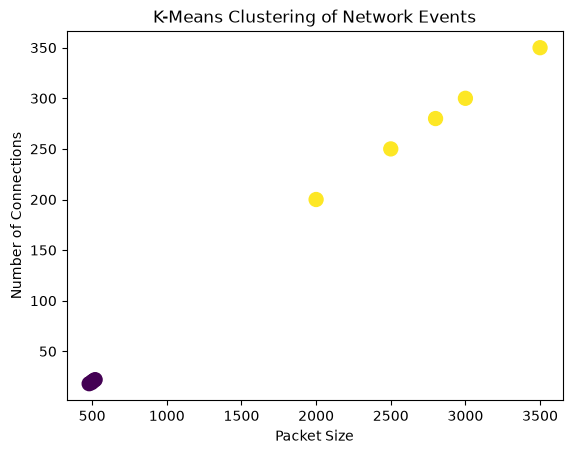

In [1]:
# Experiment 10: Use k-means to classify network events into normal and abnormal categories

# Experiment: Network Event Classification using K-Means Clustering
# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 2: Create a sample network events dataset
data = {
    'Packet_Size': [500, 520, 480, 510, 495, 2000, 2500, 3000, 2800, 3500],
    'Duration':    [10, 12, 9, 11, 10, 100, 120, 150, 130, 180],
    'Connections': [20, 22, 18, 21, 19, 200, 250, 300, 280, 350]
}

df = pd.DataFrame(data)

# Step 3: Standardize the network features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Step 4: Apply K-Means clustering with two clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Step 5: Identify the cluster with higher network activity as abnormal
cluster_means = df.groupby('Cluster')[
    ['Packet_Size', 'Duration', 'Connections']
].mean()

abnormal_cluster = cluster_means.mean(axis=1).idxmax()

# Label each event as Normal or Abnormal
df['Category'] = df['Cluster'].apply(
    lambda x: 'Abnormal' if x == abnormal_cluster else 'Normal'
)

# Step 6: Display classification results
print("Network Event Classification Results:")
print(df[['Packet_Size', 'Duration', 'Connections', 'Category']])

# Step 7: Visualize the clusters
plt.scatter(
    df['Packet_Size'], df['Connections'],
    c=df['Cluster'], cmap='viridis', s=100
)
plt.xlabel('Packet Size')
plt.ylabel('Number of Connections')
plt.title('K-Means Clustering of Network Events')
plt.show()